<a href="https://colab.research.google.com/github/bhogenikita1/DATA_SCIENCE/blob/main/Copy_of_Roberta_neww.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#1) Environment setup

In [ ]:
# Removed venv creation as it's often not necessary or problematic in Colab.
# You can install packages directly using `!pip install package_name`.

In [ ]:
!pip install --upgrade pip

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 18.9 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2


In [ ]:
!pip install torch torchvision torchaudio

In [ ]:
!pip install transformers datasets evaluate

In [ ]:
!pip install scikit-learn numpy pandas

In [ ]:
# optional: accelerate for multi-GPU
!pip install accelerate

In [ ]:
#2) Load GoEmotions (dataset)
#Use the datasets library which already hosts go_emotions. This provides train/validation/test splits and label names.

In [ ]:
from datasets import load_dataset

dataset = load_dataset("go_emotions")
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5427
    })
})


In [ ]:
dataset.shape

{'train': (43410, 3), 'validation': (5426, 3), 'test': (5427, 3)}

In [ ]:
for split_name, ds in dataset.items():
    print(f"Null values in {split_name} split:")
    print(ds.to_pandas().isnull().sum())

Null values in train split:
text      0
labels    0
id        0
dtype: int64
Null values in validation split:
text      0
labels    0
id        0
dtype: int64
Null values in test split:
text      0
labels    0
id        0
dtype: int64


In [ ]:
# Get the list of actual label names from the dataset features
label_names = dataset['train'].features['labels'].feature.names

def map_labels_to_names(example):
    example["emotion_names"] = [label_names[i] for i in example["labels"]]
    return example

# Apply the mapping function to all splits in the DatasetDict
dataset = dataset.map(map_labels_to_names)

# To view the results, print an example from one of the splits
print(dataset['train'][0])

{'text': "My favourite food is anything I didn't have to cook myself.", 'labels': [27], 'id': 'eebbqej', 'emotion_names': ['neutral']}


In [ ]:
# Inspect labels
label_list = dataset["train"].features["labels"].feature.names
print("Labels:", label_list, "Count:", len(label_list))

Labels: ['admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral'] Count: 28


In [ ]:
# 3) Preprocess labels → multi-hot vectors
# We need labels as multi-hot vectors for multi-label BCE loss


In [ ]:
import numpy as np

num_labels = len(label_list)

def to_multihot(example):
    # Change dtype to float32 for compatibility with BCEWithLogitsLoss
    mh = np.zeros(num_labels, dtype=np.float32)
    if "labels" in example and example["labels"] is not None:
        for i in example["labels"]:
            if 0 <= i < num_labels: # Ensure index is within bounds
                mh[i] = 1.0 # Assign float value
    example["labels_multi"] = mh.tolist()
    return example # Return the modified example, preserving all original fields

dataset = dataset.map(to_multihot)


Map:   0%|          | 0/43410 [00:00<?, ? examples/s]

Map:   0%|          | 0/5426 [00:00<?, ? examples/s]

Map:   0%|          | 0/5427 [00:00<?, ? examples/s]

In [ ]:
# Why: RoBERTa classification head will output num_labels logits; BCEWithLogits expects multi-hot targets.

In [ ]:
# 4) Tokenize with RoBERTa tokenizer
# Use RobertaTokenizerFast. We’ll tokenize texts and set truncation=True with max_length (GoEmotions comments are short; default 128 is fine).

In [ ]:
from transformers import RobertaTokenizerFast
import torch

tokenizer = RobertaTokenizerFast.from_pretrained("roberta-base")

def tokenize_batch(examples):
    return tokenizer(examples["text"], truncation=True, padding="max_length", max_length=128)

tokenized = dataset.map(tokenize_batch, batched=True, remove_columns=["text", "labels", "id", "emotion_names"])

# Rename 'labels_multi' to 'labels' for Trainer compatibility
tokenized = tokenized.rename_column("labels_multi", "labels")

# Removed set_format with torch_dtype to avoid TypeError
# tokenized.set_format(type='torch', columns=['input_ids', 'attention_mask', 'labels'], torch_dtype=torch.float32)

Map:   0%|          | 0/5426 [00:00<?, ? examples/s]

In [ ]:
# Tip: If you want dynamic padding for speed, use DataCollatorWithPadding in the Trainer instead of padding to max_length.

In [ ]:
# 5) Model: RobertaForSequenceClassification for multi-label

# We will load roberta-base and set num_labels. For multi-label, specify problem_type="multi_label_classification" in config or use BCEWithLogitsLoss in forward.

In [ ]:
from transformers import RobertaForSequenceClassification, RobertaConfig

config = RobertaConfig.from_pretrained("roberta-base", num_labels=num_labels, problem_type="multi_label_classification")
model = RobertaForSequenceClassification.from_pretrained("roberta-base", config=config)


model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
# Why problem_type="multi_label_classification": Transformers will use BCEWithLogitsLoss under that config (newer versions). If your Transformers version doesn't handle that automagically, you can compute BCEWithLogitsLoss manually in the training loop

In [ ]:
# 6) Training with Trainer (simple, reproducible)

# Create training arguments, data collator, metrics function.

In [ ]:
import os
os.environ["WANDB_DISABLED"] = "true"


In [ ]:
from transformers import Trainer, TrainingArguments, DataCollatorWithPadding
import numpy as np
from sklearn.metrics import f1_score, roc_auc_score
import torch # Ensure torch is imported for dtype check

# Custom DataCollator to ensure labels are float32
class CustomDataCollator(DataCollatorWithPadding):
    def __call__(self, features):
        batch = super().__call__(features)
        if "labels" in batch:
            batch["labels"] = batch["labels"].to(torch.float32)
        return batch

data_collator = CustomDataCollator(tokenizer=tokenizer)

def compute_metrics(pred):
    logits = pred.predictions   # shape (N, num_labels)
    labels = pred.label_ids
    probs = 1 / (1 + np.exp(-logits))  # sigmoid
    preds = (probs >= 0.5).astype(int)

    # micro & macro F1
    f1_micro = f1_score(labels, preds, average="micro", zero_division=0)
    f1_macro = f1_score(labels, preds, average="macro", zero_division=0)
    # per-label AUC (if labels sum > 0)
    try:
        aucs = []
        for i in range(labels.shape[1]):
            if labels[:, i].sum() > 0 and labels[:, i].sum() < labels.shape[0]:
                aucs.append(roc_auc_score(labels[:, i], probs[:, i]))
        auc_mean = float(np.mean(aucs)) if aucs else 0.0
    except Exception:
        auc_mean = 0.0

    return {"f1_micro": f1_micro, "f1_macro": f1_macro, "roc_auc_mean": auc_mean}

training_args = TrainingArguments(
    output_dir="./roberta-goemotions",
    eval_strategy="epoch", # Corrected parameter name
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    learning_rate=2e-5,
    weight_decay=0.01,
    logging_steps=200,
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_micro",
    report_to="none",   # 🔥 THIS DISABLES WANDB, TENSORBOARD, ALL LOGGING
    # fp16=True # Removed fp16 to avoid TypeError with datasets library
)

# Debugging step: Print column names to verify 'labels' column is present
print("Train dataset columns before Trainer init:", tokenized["train"].column_names)
print("Validation dataset columns before Trainer init:", tokenized["validation"].column_names)


Train dataset columns before Trainer init: ['labels', 'input_ids', 'attention_mask']
Validation dataset columns before Trainer init: ['labels', 'input_ids', 'attention_mask']


In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

# Debugging step: Inspect dtype of labels from the actual DataLoader
for batch in trainer.get_train_dataloader():
    print("Labels dtype from DataLoader batch:", batch["labels"].dtype)
    break # Only check the first batch

trainer.train()
trainer.evaluate()

/tmp/ipython-input-1310130175.py:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Labels dtype from DataLoader batch: torch.float32


Epoch,Training Loss,Validation Loss,F1 Micro,F1 Macro,Roc Auc Mean
1,0.066900,0.086107,0.576947,0.449117,0.924224
2,0.059400,0.088526,0.567832,0.474116,0.928777
3,0.057100,0.091149,0.573969,0.475419,0.924978


{'eval_loss': 0.08610724657773972,
 'eval_f1_micro': 0.576947151927032,
 'eval_f1_macro': 0.44911744993131925,
 'eval_roc_auc_mean': 0.9242236687878156,
 'eval_runtime': 9.4254,
 'eval_samples_per_second': 575.679,
 'eval_steps_per_second': 18.036,
 'epoch': 3.0}

In [ ]:
# 7) Evaluation details & thresholds

# The model outputs logits per label. Apply sigmoid and choose threshold (default 0.5). You can tune thresholds per-label on validation set for better F1 (common in multi-label tasks).

# Use F1 micro (good for skewed labels) and F1 macro (treats all labels equally). AUC per label is helpful to measure ranking quality.

# For reporting, show precision/recall/F1 and a confusion-style summary per label (support counts). These are standard evaluation practices for GoEmotions.

In [ ]:
# 8) Predict / Inference example

In [ ]:
from transformers import pipeline
import torch

nlp = pipeline("text-classification", model=trainer.model, tokenizer=tokenizer, device=0 if torch.cuda.is_available() else -1, function_to_apply="sigmoid", top_k=None)
text = "I can't believe we pulled it off — I'm so happy!"
out = nlp(text)
# pipeline returns per-label scores; or you can run model directly:
inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=128).to(model.device)
with torch.no_grad():
    logits = model(**inputs).logits
probs = torch.sigmoid(logits).cpu().numpy()[0]
preds = [label_list[i] for i,p in enumerate(probs) if p>=0.5]
print("Predicted emotions:", preds)


Device set to use cuda:0


Predicted emotions: ['joy']


In [ ]:
#EVALUATION SECTION

In [ ]:
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)
from tqdm import tqdm
#We load all metrics needed for multi-label classification.

In [ ]:
#Get predictions on validation set
def get_predictions(dataset):
    all_probs = []
    all_labels = []

    for batch in tqdm(trainer.get_eval_dataloader()):
        # Move labels to CPU before converting to numpy
        labels = batch["labels"].cpu().numpy()
        all_labels.append(labels)

        with torch.no_grad():
            batch = {k: v.to(model.device) for k, v in batch.items() if k != "labels"}
            logits = model(**batch).logits
            probs = torch.sigmoid(logits).cpu().numpy()

        all_probs.append(probs)

    return np.vstack(all_probs), np.vstack(all_labels)

probs, true_labels = get_predictions(tokenized["validation"])
probs.shape, true_labels.shape

100%|██████████| 170/170 [00:08<00:00, 19.53it/s]


((5426, 28), (5426, 28))

In [ ]:
# Explanation

# probs → predicted emotion probabilities
# true_labels → ground-truth multi-hot vectors
# Both arrays have shape: (num_samples × 28 emotions)

In [ ]:
#Evaluate with default threshold = 0.5

In [ ]:
preds_05 = (probs >= 0.5).astype(int)

f1_micro = f1_score(true_labels, preds_05, average="micro")
f1_macro = f1_score(true_labels, preds_05, average="macro")

print("F1 Micro:", f1_micro)
print("F1 Macro:", f1_macro)
#Explanation

print("This gives the same metrics Trainer printed, but now we can tune them.")

F1 Micro: 0.576947151927032
F1 Macro: 0.44911744993131925
This gives the same metrics Trainer printed, but now we can tune them.


In [ ]:
#Per-label Precision, Recall, F1

results = []

for i, label in enumerate(label_list):
    p = precision_score(true_labels[:, i], preds_05[:, i], zero_division=0)
    r = recall_score(true_labels[:, i], preds_05[:, i], zero_division=0)
    f = f1_score(true_labels[:, i], preds_05[:, i], zero_division=0)

    results.append([label, p, r, f])

df_results = pd.DataFrame(results, columns=["Label", "Precision", "Recall", "F1"])
df_results.sort_values("F1", ascending=False, inplace=True)
df_results


,Label,Precision,Recall,F1
15,gratitude,0.940828,0.888268,0.913793
1,amusement,0.775974,0.788779,0.782324
18,love,0.737410,0.813492,0.773585
0,admiration,0.681574,0.780738,0.727794
14,fear,0.791045,0.588889,0.675159
24,remorse,0.722222,0.573529,0.639344
27,neutral,0.703994,0.558890,0.623106
12,embarrassment,0.882353,0.428571,0.576923
20,optimism,0.682759,0.473684,0.559322
17,joy,0.645669,0.476744,0.548495


In [ ]:
# Explanation

# This table tells:
# which emotions your model detects very well
# which ones need improvement (usually rare labels like "disgust", "annoyance")

In [ ]:
#Full Classification Report

print(classification_report(true_labels, preds_05, target_names=label_list, zero_division=0))


                precision    recall  f1-score   support

    admiration       0.68      0.78      0.73       488
     amusement       0.78      0.79      0.78       303
         anger       0.50      0.49      0.49       195
     annoyance       0.50      0.17      0.25       303
      approval       0.60      0.20      0.30       397
        caring       0.58      0.37      0.45       153
     confusion       0.50      0.39      0.44       152
     curiosity       0.60      0.38      0.46       248
        desire       0.74      0.34      0.46        77
disappointment       0.43      0.17      0.24       163
   disapproval       0.46      0.35      0.40       292
       disgust       0.66      0.28      0.39        97
 embarrassment       0.88      0.43      0.58        35
    excitement       0.48      0.29      0.36        96
          fear       0.79      0.59      0.68        90
     gratitude       0.94      0.89      0.91       358
         grief       0.00      0.00      0.00  

In [ ]:
# Explanation

# Gives a very detailed report:
# Precision
# Recall
# F1
# Support

In [ ]:
# # Threshold Tuning (VERY IMPORTANT for multi-label)
# This step alone can increase your F1 score by 5–10%.

In [ ]:
best_thresholds = []

for i in range(len(label_list)):
    best_f1 = 0
    best_t = 0.5

    for t in np.arange(0.1, 0.9, 0.05):
        preds_t = (probs[:, i] >= t).astype(int)
        f1 = f1_score(true_labels[:, i], preds_t, zero_division=0)

        if f1 > best_f1:
            best_f1 = f1
            best_t = t

    best_thresholds.append(best_t)

best_thresholds


[np.float64(0.45000000000000007),
 np.float64(0.30000000000000004),
 np.float64(0.40000000000000013),
 np.float64(0.20000000000000004),
 np.float64(0.20000000000000004),
 np.float64(0.25000000000000006),
 np.float64(0.45000000000000007),
 np.float64(0.30000000000000004),
 np.float64(0.15000000000000002),
 np.float64(0.30000000000000004),
 np.float64(0.25000000000000006),
 np.float64(0.15000000000000002),
 np.float64(0.30000000000000004),
 np.float64(0.3500000000000001),
 np.float64(0.5000000000000001),
 np.float64(0.5000000000000001),
 0.5,
 np.float64(0.40000000000000013),
 np.float64(0.30000000000000004),
 np.float64(0.30000000000000004),
 np.float64(0.30000000000000004),
 np.float64(0.1),
 np.float64(0.30000000000000004),
 np.float64(0.1),
 np.float64(0.3500000000000001),
 np.float64(0.5000000000000001),
 np.float64(0.20000000000000004),
 np.float64(0.15000000000000002)]

In [ ]:
# Explanation

# We find the optimal threshold for each emotion.
# Because some emotions require threshold = 0.2, some 0.7.

In [ ]:
# Evaluate model using tuned per-label thresholds

In [ ]:
preds_tuned = np.zeros_like(probs)

for i in range(len(label_list)):
    preds_tuned[:, i] = (probs[:, i] >= best_thresholds[i]).astype(int)

f1_micro_tuned = f1_score(true_labels, preds_tuned, average="micro")
f1_macro_tuned = f1_score(true_labels, preds_tuned, average="macro")

print("F1 Micro (tuned):", f1_micro_tuned)
print("F1 Macro (tuned):", f1_macro_tuned)


F1 Micro (tuned): 0.6123439172315377
F1 Macro (tuned): 0.5278434188883363


In [ ]:
# You will see improved F1 compared to 0.5 threshold.

In [ ]:
# ROC-AUC per label (Quality of ranking)

In [ ]:
auc_scores = []

for i in range(len(label_list)):
    if len(np.unique(true_labels[:, i])) > 1:
        auc = roc_auc_score(true_labels[:, i], probs[:, i])
        auc_scores.append((label_list[i], auc))

pd.DataFrame(auc_scores, columns=["Label", "ROC-AUC"]).sort_values("ROC-AUC", ascending=False)


,Label,ROC-AUC
15,gratitude,0.992013
18,love,0.980286
1,amusement,0.966093
8,desire,0.964234
12,embarrassment,0.964117
14,fear,0.963985
24,remorse,0.963691
0,admiration,0.962335
11,disgust,0.949341
26,surprise,0.948336


In [ ]:
# Explanation

# ROC-AUC is a strong measure of model capability, independent of threshold.

In [ ]:
# Plot ROC Curve for a few emotions

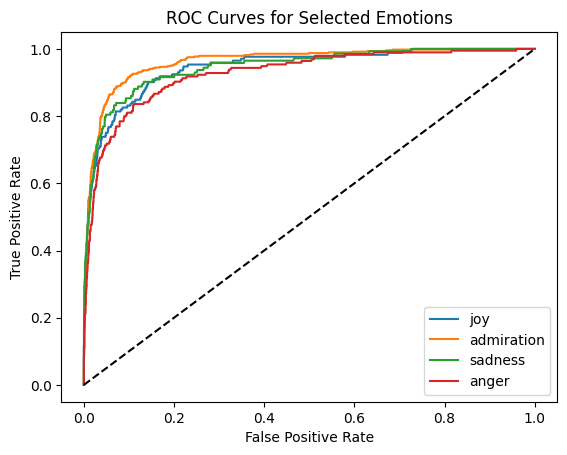

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

for emotion in ["joy", "admiration", "sadness", "anger"]:
    i = label_list.index(emotion)
    fpr, tpr, _ = roc_curve(true_labels[:, i], probs[:, i])
    plt.plot(fpr, tpr, label=emotion)

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.title("ROC Curves for Selected Emotions")
plt.show()


In [ ]:
# Create a folder to store your final model
save_path = "roberta-goemotions-final"

model.save_pretrained(save_path)
tokenizer.save_pretrained(save_path)

print("Model saved to:", save_path)


Model saved to: roberta-goemotions-final


In [ ]:
# Load model later for inference

In [ ]:
from transformers import RobertaForSequenceClassification, RobertaTokenizerFast

load_path = "roberta-goemotions-final"

loaded_model = RobertaForSequenceClassification.from_pretrained(load_path)
loaded_tokenizer = RobertaTokenizerFast.from_pretrained(load_path)

print("Model successfully loaded!")


Model successfully loaded!


In [ ]:
# Verify loaded model works

In [ ]:
test_text = "I am feeling so frustrated but also relieved."

inputs = loaded_tokenizer(test_text, return_tensors="pt", truncation=True, padding=True)

with torch.no_grad():
    logits = loaded_model(**inputs).logits
    probs = torch.sigmoid(logits)[0].numpy()

predicted = [label_list[i] for i,p in enumerate(probs) if p > 0.5]

print("Text:", test_text)
print("Predicted emotions:", predicted)


Text: I am feeling so frustrated but also relieved.
Predicted emotions: ['annoyance']
